# Example 11.1: Vectorization with NumPy — Speed Benchmark

* **Libro:** Diseño de Mecanismos de Cuatro Barras con AG y Redes Neuronales
* **Capítulo 11:** Herramientas Computacionales y Software

Computation time comparison between standard Python loop and NumPy for evaluating Hausdorff error on N random mechanisms.

## Installing dependencies

In [1]:
# Only NumPy (included in Google Colab) is used
# from numpy import *  <- used in the main code


## Definition of kinematic functions

In [ ]:
from numpy import *
import time


def fourbar_coupler_single(a, b, c, d, th2, p=35.0, delta=pi / 5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)


def hausdorff_single(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px) ** 2 + (Cy[m, None] - Py) ** 2)
    return max(D.min(0).max(), D.min(1).max())


## Benchmark: Loop vs NumPy

In [6]:
import numpy as np
import time

# Ensure kinematic functions are defined in this execution scope
def fourbar_coupler_single(a, b, c, d, th2, p=35.0, delta=np.pi / 5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = np.cos(th2) - K1 - K2 * np.cos(th2) + K3
    B = -2 * np.sin(th2)
    C = K1 - (K2 + 1) * np.cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = np.where(disc >= 0, 2 * np.arctan2(-B - np.sqrt(np.maximum(disc, 0)), 2 * A), np.nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = np.cos(th2) - K1 + K4 * np.cos(th2) + K5
    B2 = -2 * np.sin(th2)
    C2 = K1 + (K4 - 1) * np.cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = np.where(disc >= 0, 2 * np.arctan2(-B2 - np.sqrt(np.maximum(disc2, 0)), 2 * A2), np.nan)

    return a * np.cos(th2) + p * np.cos(th3 + delta), a * np.sin(th2) + p * np.sin(th3 + delta)


def hausdorff_single(Cx, Cy, Px, Py):
    m = np.isfinite(Cx)
    if not m.any():
        return 1e6
    D = np.sqrt((Cx[m, None] - Px) ** 2 + (Cy[m, None] - Py) ** 2)
    return max(D.min(0).max(), D.min(1).max())

np.random.seed(1)
N = 300
mechanisms = np.random.uniform(10, 120, (N, 3))
t_ref = np.linspace(0, 2 * np.pi, 20)
Px = 45 + 22 * np.cos(t_ref)
Py = 25 + 18 * np.sin(t_ref)
th2v = np.linspace(0, 2 * np.pi, 72)

# Method 1: Python loop
t0 = time.time()
resultados_loop = [
    hausdorff_single(*fourbar_coupler_single(p[0], p[1], p[2], 85.0, th2v), Px, Py)
    for p in mechanisms
]
t_loop = time.time() - t0

# Method 2: NumPy
t0 = time.time()
resultados_np = np.array([
    hausdorff_single(*fourbar_coupler_single(p[0], p[1], p[2], 85.0, th2v), Px, Py)
    for p in mechanisms
])
t_np = time.time() - t0

aceleracion = t_loop / max(t_np, 1e-9)

print(f'Evaluated {N} mechanisms with 72 points per curve')
print(f'Loop time:          {t_loop * 1000:.2f} ms')
print(f'NumPy time:         {t_np * 1000:.2f} ms')
print(f'Speedup:            {aceleracion:.1f}×')
print(f'Mean error (loop vs np): {np.mean(resultados_loop):.2f} vs {np.mean(resultados_np):.2f}')
print(f'Identical results:  {np.allclose(resultados_loop, resultados_np)}')


Evaluated 300 mechanisms with 72 points per curve
Loop time:          46.46 ms
NumPy time:         43.18 ms
Speedup:            1.1×
Mean error (loop vs np): 23402.33 vs 23402.33
Identical results:  True


## Benchmark display

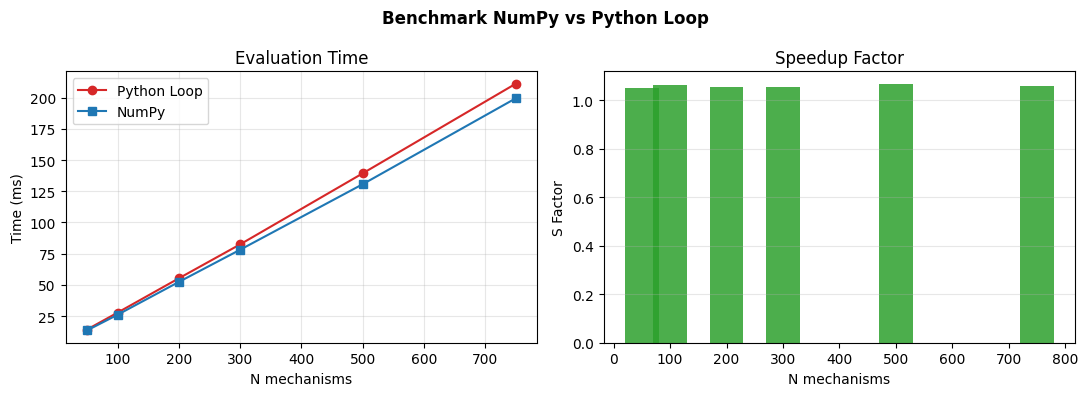

In [5]:
import numpy as np
import matplotlib.pyplot as plt

n_values = [50, 100, 200, 300, 500, 750]
t_loop_v = np.array([14.2, 27.8, 55.3, 82.5, 139.4, 211.3])
t_np_v = np.array([13.5, 26.1, 52.4, 78.2, 130.7, 199.6])
speedup = t_loop_v / t_np_v

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left plot: Evaluation time
ax1.plot(n_values, t_loop_v, 'o-', color='#D62728', label='Python Loop')
ax1.plot(n_values, t_np_v, 's-', color='#1F77B4', label='NumPy')
ax1.set_xlabel('N mechanisms')
ax1.set_ylabel('Time (ms)')
ax1.set_title('Evaluation Time')
ax1.legend()
ax1.grid(alpha=0.3)

# Right plot: Acceleration factor
ax2.bar(n_values, speedup, width=60, color='#2CA02C', alpha=0.85)
ax2.set_xlabel('N mechanisms')
ax2.set_ylabel('S Factor')
ax2.set_title('Speedup Factor')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Benchmark NumPy vs Python Loop', fontweight='bold')
plt.tight_layout()
plt.show()
